Training complete!
Greedy path reached goal: True
Path: [(np.int64(0), np.int64(0)), (np.int64(1), np.int64(0)), (np.int64(2), np.int64(0)), (np.int64(3), np.int64(0)), (np.int64(4), np.int64(0)), (np.int64(4), np.int64(1)), (np.int64(4), np.int64(2)), (np.int64(4), np.int64(3)), (np.int64(4), np.int64(4)), (np.int64(4), np.int64(5)), (np.int64(5), np.int64(5)), (np.int64(6), np.int64(5)), (np.int64(6), np.int64(6)), (np.int64(6), np.int64(7)), (np.int64(5), np.int64(7))]


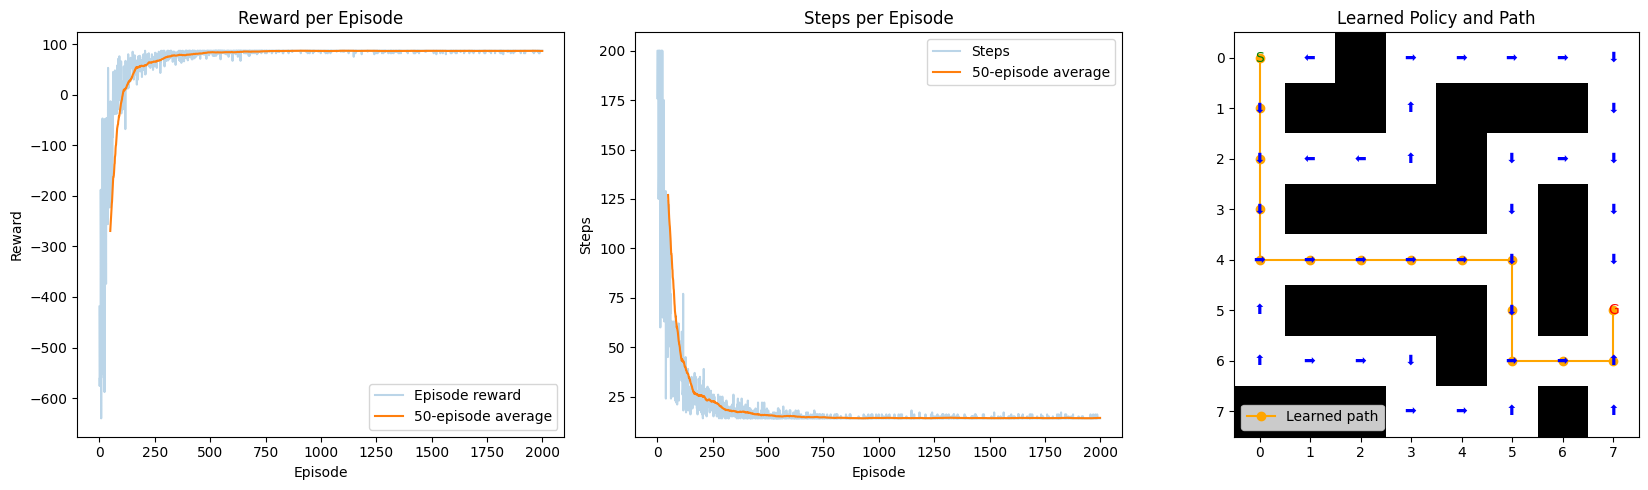

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Maze: S = start, G = goal, # = wall
maze = [
    "S.#.....",
    ".##.###.",
    "....#...",
    ".####.#.",
    "......#.",
    ".####.#G",
    "....#...",
    "###...#."
]

grid = np.array([list(row) for row in maze])
rows, cols = grid.shape
start = tuple(np.argwhere(grid == "S")[0])
goal = tuple(np.argwhere(grid == "G")[0])

# Actions: up, down, left, right
moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]
arrows = ["⬆️", "⬇️", "⬅️", "➡️"]

# Q[state row, state col, action]
Q = np.zeros((rows, cols, 4))

alpha = 0.1       # learning rate
gamma = 0.95      # discount factor
epsilon = 1.0     # exploration rate
episodes = 2000
max_steps = 200

rng = np.random.default_rng(42)
episode_rewards = []
episode_steps = []

# Train using Q-learning
for episode in range(episodes):
    state = start
    total_reward = 0

    for step_num in range(max_steps):
        # Choose an action: explore or use the best known action
        if rng.random() < epsilon:
            action = int(rng.integers(4))
        else:
            action = int(np.argmax(Q[state]))

        # Apply the action
        row, col = state
        dr, dc = moves[action]
        next_row, next_col = row + dr, col + dc

        # Determine next state, reward, and whether the episode ends
        if (next_row < 0 or next_row >= rows or
            next_col < 0 or next_col >= cols or
            grid[next_row, next_col] == "#"):
            next_state, reward, done = state, -5, False
        else:
            next_state = (next_row, next_col)
            if next_state == goal:
                reward, done = 100, True
            else:
                reward, done = -1, False

        # Q-learning update
        best_future = 0 if done else np.max(Q[next_state])
        Q[state][action] += alpha * (
            reward + gamma * best_future - Q[state][action]
        )

        state = next_state
        total_reward += reward

        if done:
            break

    episode_rewards.append(total_reward)
    episode_steps.append(step_num + 1)

    # Gradually reduce exploration
    epsilon = max(0.01, epsilon * 0.995)

# Follow the learned best actions from start
state = start
path = [state]
reached_goal = False

for _ in range(rows * cols):
    action = int(np.argmax(Q[state]))
    dr, dc = moves[action]
    next_state = (state[0] + dr, state[1] + dc)

    # Stop if the learned action hits a wall or boundary
    if (next_state[0] < 0 or next_state[0] >= rows or
        next_state[1] < 0 or next_state[1] >= cols or
        grid[next_state] == "#"):
        break

    state = next_state
    path.append(state)

    if state == goal:
        reached_goal = True
        break

print("Training complete!")
print("Greedy path reached goal:", reached_goal)
print("Path:", path)

# Moving averages smooth the first two graphs
window = 50
avg_rewards = np.convolve(
    episode_rewards, np.ones(window) / window, mode="valid"
)
avg_steps = np.convolve(
    episode_steps, np.ones(window) / window, mode="valid"
)

# Plot the three graphs
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. Reward per episode
axes[0].plot(episode_rewards, alpha=0.3, label="Episode reward")
axes[0].plot(
    range(window - 1, episodes),
    avg_rewards,
    label="50-episode average"
)
axes[0].set(title="Reward per Episode", xlabel="Episode", ylabel="Reward")
axes[0].legend()

# 2. Steps per episode
axes[1].plot(episode_steps, alpha=0.3, label="Steps")
axes[1].plot(
    range(window - 1, episodes),
    avg_steps,
    label="50-episode average"
)
axes[1].set(title="Steps per Episode", xlabel="Episode", ylabel="Steps")
axes[1].legend()

# 3. Maze, policy arrows, and learned path
maze_image = np.zeros((rows, cols))
maze_image[grid == "#"] = 1
axes[2].imshow(maze_image, cmap="Greys", vmin=0, vmax=1)

for r in range(rows):
    for c in range(cols):
        if grid[r, c] == "#":
            continue
        if (r, c) == start:
            label, color = "S", "green"
        elif (r, c) == goal:
            label, color = "G", "red"
        elif np.max(Q[r, c]) != 0:
            label, color = arrows[np.argmax(Q[r, c])], "blue"
        else:
            continue
        axes[2].text(c, r, label, ha="center", va="center", color=color)

# Draw the path
if len(path) > 1:
    path_rows, path_cols = zip(*path)
    axes[2].plot(path_cols, path_rows, "o-", color="orange", label="Learned path")

axes[2].set(title="Learned Policy and Path", xticks=range(cols), yticks=range(rows))
axes[2].legend()

plt.tight_layout()
plt.show()